In [1]:
# import cython
import numpy as np
import matplotlib.pyplot as plt 
import glob
import os

from joblib import Parallel, delayed
import multiprocessing as mp

In [2]:
import torch
from unet import UNet
import torchvision.transforms as transforms

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

# if not torch.backends.mps.is_available():
#     if not torch.backends.mps.is_built():
#         print("MPS not available because the current PyTorch install was not "
#               "built with MPS enabled.")
#     else:
#         print("MPS not available because the current MacOS version is not 12.3+ "
#               "and/or you do not have an MPS-enabled device on this machine.")

# else:
#     device = torch.device("mps")

cuda:0


In [3]:
target_size = [408, 512]
model = UNet(n_channels=1, n_classes=2, input_size=target_size, in_dropout_p = 0.3, dropout_p=0.3)
saved_model_dir = '/media/jackle/LData/MLvipir_save/save_model_latest/'
model.load_state_dict(torch.load(saved_model_dir+'CEbycol_20ktrain_set_epoch_40_18000_loss0.0000.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (att): Transformer(
    (in_linear): Linear(in_features=512, out_features=1024, bias=True)
    (out_linear): Linear(in_features=1024, out_features=1024, bias=True)
    (blocks): Sequential(
      (0): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): GELU(approximate='none')
        )
        (mhatt): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=1024, out_features=1024, bias=True)
        )
        (relu): GELU(approximate='none')
        (ln): GroupNorm(1, 408, eps=1e-05, affine=True)
      )
      (1): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): GELU(approximate='none')
        )
        (mhatt): MultiheadAttention(
   

In [4]:
from torch.utils.data import DataLoader
from fakeionogramdatasetOX import ParabolaIonoDatasetOX

loader_args = dict(batch_size=5,  pin_memory=True, num_workers=5)
train_dataset = ParabolaIonoDatasetOX('training_data', target_size= target_size, resize='pad')
train_loader = DataLoader(train_dataset, shuffle=True, drop_last=True, **loader_args)

In [5]:
data = next(iter(train_loader))
print(data['image'].size())
print(data['gt'].size())

torch.Size([5, 1, 408, 512])
torch.Size([5, 2, 408])


In [6]:
result = model(data['image'].to(device))

In [7]:
result.size()
idx = 1


In [8]:
import torch.nn as nn

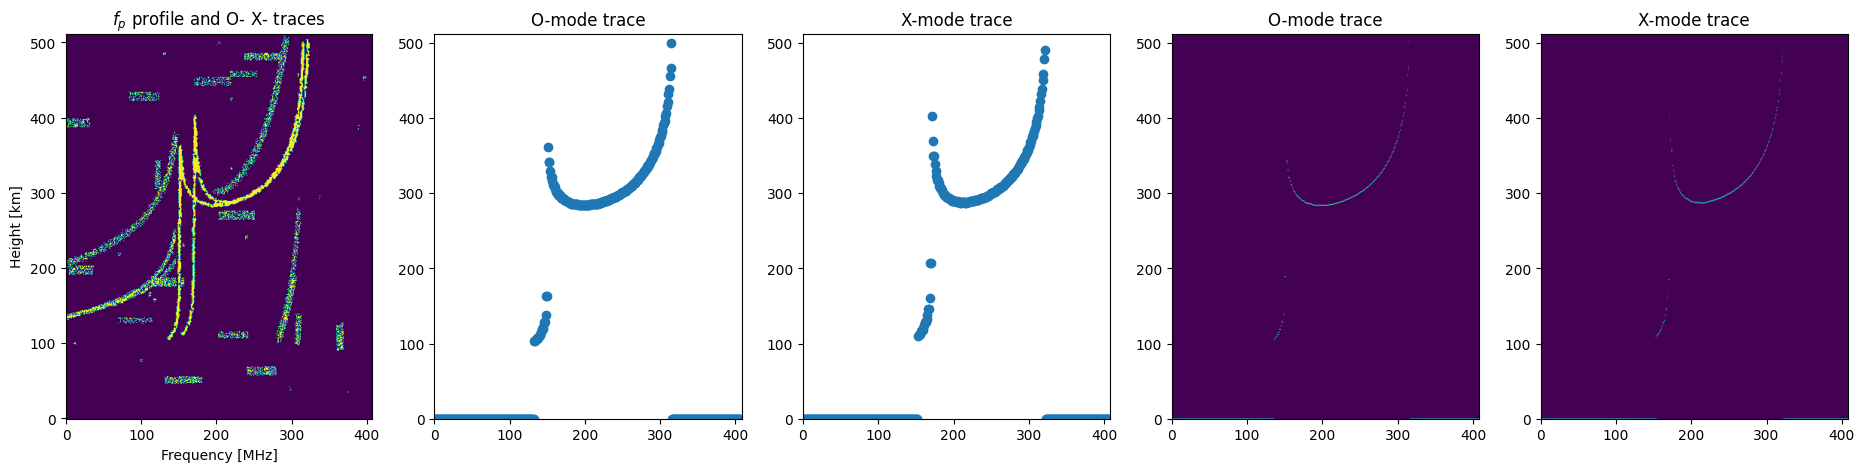

In [22]:
softmax = nn.Softmax(dim=-1)

fig,axes = plt.subplots(1,5,figsize=(23.0,5.0),sharex=False)
ax1 = axes[0]

ax1.imshow(data['image'][idx,0,:,:].T,origin='lower')
ax1.set_title(r'$f_p$ profile and O- X- traces')
ax1.set_xlabel('Frequency [MHz]')
ax1.set_ylabel('Height [km]')
# ax1.legend()

ovhidx = data['gt'][idx,0,:]
xvhidx = data['gt'][idx,1,:]

# print(ovhidx )
ax2 = axes[1]
# ax2.imshow(np.vstack([opres]*data['image'].shape[2]),origin='lower')
ax2.scatter(np.arange(ovhidx.shape[0]), ovhidx)
ax2.set_title('O-mode trace')
ax2.set_xlim(0,408)
ax2.set_ylim(0,512)

ax3 = axes[2]
# ax3.imshow(np.vstack([xpres]*data['image'].shape[2]),origin='lower')
ax3.scatter(np.arange(xvhidx.shape[0]), xvhidx)
ax3.set_title('X-mode trace')
ax3.set_xlim(0,408)
ax3.set_ylim(0,512)

# opres  = torch.sigmoid(result[idx,0,:]).detach().cpu().numpy()
# ovhidx = torch.sigmoid(result[idx,1,:]).detach().cpu().numpy()*512
# xpres  = torch.sigmoid(result[idx,2,:]).detach().cpu().numpy()
# xvhidx = torch.sigmoid(result[idx,3,:]).detach().cpu().numpy()*512

imgO = softmax(result[idx,0,:,:].cpu()).detach().numpy()
imgX = softmax(result[idx,1,:,:].cpu()).detach().numpy()

ax4 = axes[3]
# ax4.imshow(np.vstack([opres]*data['image'].shape[2]),origin='lower')
# ax4.scatter(np.arange(opres.shape[0]), ovhidx)
ax4.imshow(imgO.T, origin='lower', aspect = 'auto')
ax4.set_title('O-mode trace')
ax4.set_xlim(0,408)
ax4.set_ylim(0,512)

ax5 = axes[4]
# ax5.imshow(np.vstack([xpres]*data['image'].shape[2]),origin='lower')
# ax5.scatter(np.arange(xpres.shape[0]), xvhidx)
ax5.imshow(imgX.T, origin='lower', aspect = 'auto')
ax5.set_title('X-mode trace')
ax5.set_xlim(0,408)
ax5.set_ylim(0,512)

idx = (idx+1)%5

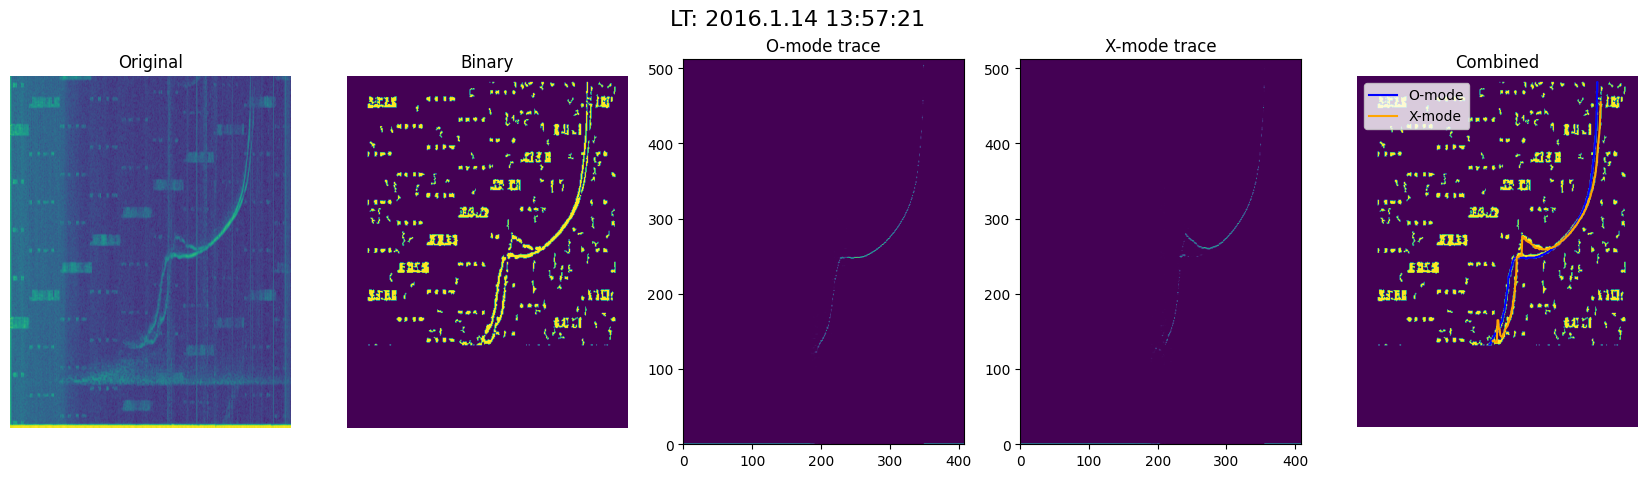

In [ ]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
 
with torch.no_grad():
    for file in testfiles:
        # file = testfiles[np.random.randint(0,len(testfiles)-1)]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

        orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
        # for i in orgdata:
        #     print(i)
        timestruct = orgdata['vipirTimeSct']
        localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"

        # print(timestruct)
        
        testimage1 = torch.from_numpy(testdata['mask_full'].T).float()
        testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
        img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)

        result = model(img.to('cuda'))
        
        imgO = softmax(result[idx,0,:,:].cpu()).detach().numpy()
        imgX = softmax(result[idx,1,:,:].cpu()).detach().numpy()

        vhidxO = np.argmax(imgO, axis=-1)
        vhidxX = np.argmax(imgX, axis=-1)

        fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))
        # plt.title(f'epoch{epoch_num}_{file}')
        fig.suptitle(f'{localtime}', fontsize=16)

        ax = axs[0]
        ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Original')

        ax = axs[1]
        ax.imshow(testimage1.detach().squeeze().T, origin='lower', aspect = 'equal')
        ax.axis('off')
        ax.set_title('Binary')
        
        ax4 = axs[2]
        ax4.set_title('O-mode trace')
        ax4.imshow(imgO.T, origin='lower', aspect = 'auto')
        ax4.set_xlim(0,408)
        ax4.set_ylim(0,512)

        ax5 = axs[3]
        ax5.set_title('X-mode trace')
        ax5.imshow(imgX.T, origin='lower', aspect = 'auto')
        ax5.set_xlim(0,408)
        ax5.set_ylim(0,512)


        ax = axs[4]
        ax.imshow(testimage1.detach().squeeze().T, origin='lower', aspect = 'equal')
        ax.plot(np.nonzero(vhidxO)[0], vhidxO[np.nonzero(vhidxO)], label='O-mode', color='blue')
        ax.plot(np.nonzero(vhidxX)[0], vhidxX[np.nonzero(vhidxX)], label='X-mode', color='orange')
        ax.legend()
        ax.axis('off')
        ax.set_title('Combined')
        ax.set_ylim(1,512)

        # break
        plt.savefig(f'testing_result/{file[:-4]}.png', bbox_inches='tight')
        plt.close()


In [3]:
def dist_loss(input, model): # radius is the maxmum loss between two points. 
    loss = 0.0
    if input.shape[0] == 0:
        return 0
    for point in input:
        error = (np.min(np.sum((model-point)**2, axis = 1)))
        loss += error
    loss = loss/input.shape[0]
    # print(input.shape[0])
    # print(model.shape)
    return loss

In [4]:
target_size = [512,408]
# saved_model_dir = 'saved_model/'
saved_model_dir = '/media/jackle/LData/MLvipir_save/save_model_latest/'

savedmodel_list = glob.glob1(saved_model_dir,'TOPHAT_checkpoint_epoch_*')
savedmodel_list.sort()
print(len(savedmodel_list))

testfiles = glob.glob1('VIPIR_PROC/labeled/','*.npy')
testfiles.sort()
evalresult = {}

print(len(testfiles))


46
200


In [5]:
outdir = 'Testfitting_eval_model/'
# evalresult = np.load(outdir+'evalresult_file.npy', allow_pickle=True, fix_imports=True)[()]
print(len(evalresult))

0


In [6]:
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.3, dropout_p=0.3)
model = model.to(device=device)

batchsize = 10
for f in savedmodel_list[:]:
    if not os.path.exists(outdir+f):
        os.makedirs(outdir+f)
    state_data = torch.load(saved_model_dir+f, weights_only=True)
    model.load_state_dict(state_data['model_state_dict'])
    model.eval()
    with torch.inference_mode():
        for ii in range(len(testfiles)//batchsize):
            img = []
            names = []
            for jj in range(batchsize):
                file = testfiles[ii*batchsize + jj]
                testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
                testimage = torch.from_numpy(testdata['mask_full']).float()
                testimage = testimage[None,None,:,:]
                img += [testimage]
                names += [file]

            img = torch.cat(img,dim=0)
            img = img.to('cuda')
            label = model(img)
            
            for i in range(batchsize):
                img1,label1 = img[i],label[i]
                label1 = label1.squeeze().to('cpu')
                imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().numpy()
                imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().numpy()

                np.save(outdir+f'{f}/{names[i]}', {'imgO': imgO, 'imgX': imgX})
            
            del label; del img; del names
    del state_data
                

In [7]:
def eval_one_file (outdir, file):
    segresult = np.load(outdir+file, allow_pickle=True, fix_imports=True)[()]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
    labeldata = np.load('VIPIR_PROC/labeled/' + file, allow_pickle=True, fix_imports=True)[()]

    imgO = segresult['imgO']
    imgX = segresult['imgX']

    Y, X = imgO.nonzero()
    inputO = np.vstack((X,Y)).T

    Y, X = imgX.nonzero()
    inputX = np.vstack((X,Y)).T

    otrace = labeldata['otrace']
    Y, X = otrace.nonzero()
    targetO = np.vstack((X,Y)).T

    xtrace = labeldata['xtrace']
    Y, X = xtrace.nonzero()
    targetX = np.vstack((X,Y)).T

    loss = dist_loss(inputO, targetO)
    loss += dist_loss(inputX, targetX)

    fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(18, 5))
    fig.suptitle(f'{file} loss:{loss}', fontsize=16)

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[1]
    ax.imshow(testdata['mask_full'], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[2]
    ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output Combined')

    ax = axs[3]
    ax.imshow(otrace + 2*xtrace, origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('GT Combined')

    fig.savefig(outdir+f'/{file[:-4]}.png', bbox_inches='tight')
    plt.close()
    
    return loss

In [8]:
for f in savedmodel_list:
    if f in evalresult:
        continue

    para_func = lambda file: eval_one_file(f'{outdir+f}/',file)

    losses = Parallel(n_jobs=mp.cpu_count()-4)(delayed(para_func)(file) for file in testfiles)
    
    checkpoint_result = {testfiles[i]:losses[i] for i in range(len(losses))}    

    np.save(outdir+f'{f}/checkpoint_result.npy', checkpoint_result)
    
    mean_loss = np.sum(losses)/len(testdata)
    evalresult[f] = mean_loss
    print(mean_loss)
    np.save(outdir+f'evalresult_file.npy', evalresult)
    with open(outdir+"evalresult_file.txt", "w") as txt:
        for i in evalresult:
            txt.write(f'{evalresult[i]}, {i}\n')

7991.087174178633
7030.983331941445
6525.7410907157155
5483.557927387077
6373.087999836012
4992.204718775294
5807.965237493089
3946.9485718613205
4374.241749506635
2949.497200429634
1560924.1662159024
101474.98621466088
3238.9962551731983
5031.208313010591
2806.8149843718484
2055.7517155585815
2711.057415637828
1916.0721411983418
2054.664669879621
2474.206142894828
1958.5393786119812
3067.376013436662
84780.94238256641
2329.0653683824626
2283.5654283285767
1453.9727437815714
1987.909467421432
2196.5093533415693
2377.1107483950723
1792.7724439965632
1848.5321358678646
2088.70810360965
2267.5624087561464
23413.06445065693
2606.799325741323
2110.482669960784
2132.8881101735096
2104.8766033284082
2162.128292485997
1653.2161199373609
9389.262764265703
11304.055255639922
7067.393748822536
6356.763408354222
23812.277686560592
6931.8682038734505


In [ ]:
# load_checkpoint = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_30_45000_loss1.3968.pth')
# test_losses_old   = load_checkpoint['test_loss']
# losses_old = load_checkpoint['train_loss']
# for f in savedmodel_list:
#     load_checkpoint = torch.load('saved_model/'+f)
#     test_losses   = load_checkpoint['test_loss']
#     losses   = load_checkpoint['train_loss']
#     print(len(test_losses))
#     if len(test_losses) > 60:
#         losses = losses_old + losses
#         for i in range(61):
#             test_losses[i] = test_losses_old[i]
#     else:
#         continue
#     load_checkpoint['test_loss'] = test_losses
#     load_checkpoint['train_loss'] = losses
#     torch.save(load_checkpoint, f'saved_model/{f}')

In [9]:
# evalresult_filtered = {}
# for k in evalresult:
#     segs = k.split('_')
#     if segs[4] == '36000':
#         continue
#     else:
#         evalresult_filtered[k] = evalresult[k]
print(len(evalresult))

46


In [ ]:
# evalresult = evalresult_filtered

loss = [evalresult[l] for l in evalresult]
filenames = [l for l in evalresult]

# plt.plot(np.log10(loss))
# print(filenames)

# temp = sorted(evalresult, key=lambda e : evalresult[e], reverse=True)
def key_func(s: str) -> float:
    segs = s.split('_')
    return float(segs[3])+float(segs[4])/36000

sort_by_epoch = sorted(evalresult, key=key_func, reverse=False)
sort_by_loss = sorted(evalresult, key=lambda e : evalresult[e], reverse=True)

# print(sort_by_epoch)
# print(sort_by_loss)
data = torch.load(saved_model_dir+sort_by_epoch[-1])
test_losses = data['test_loss']
sort_by_dice = [sort_by_epoch[j] for j in sorted(list(range(len(test_losses))), key=lambda i : test_losses[i], reverse=False)]
print(sort_by_dice[-5:])

fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(10, 4))
ax = axs[0]
ax.plot(test_losses)
ax.set_ylim(1.05,1.85)
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*1])
ax.set_ylabel('Dice score O+X')
ax.set_xlabel('Epoch')
ax.set_title('Dice score on manually labeled ionograms')

ax = axs[1]
ax.plot([evalresult[t] for t in sort_by_epoch])
ax.plot([evalresult[t] for t in sort_by_loss])
ax.set_ylim(1000,8000)
ax.set_ylabel('Dist loss O+X')
ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*1])

print(sort_by_loss[-5:])

IndexError: list index out of range

/tmp/ipykernel_10882/3922038133.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0,0.1)
/tmp/ipykernel_10882/3922038133.py:31: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0,0.1)


Text(0, 0.5, 'Dice score O+X')

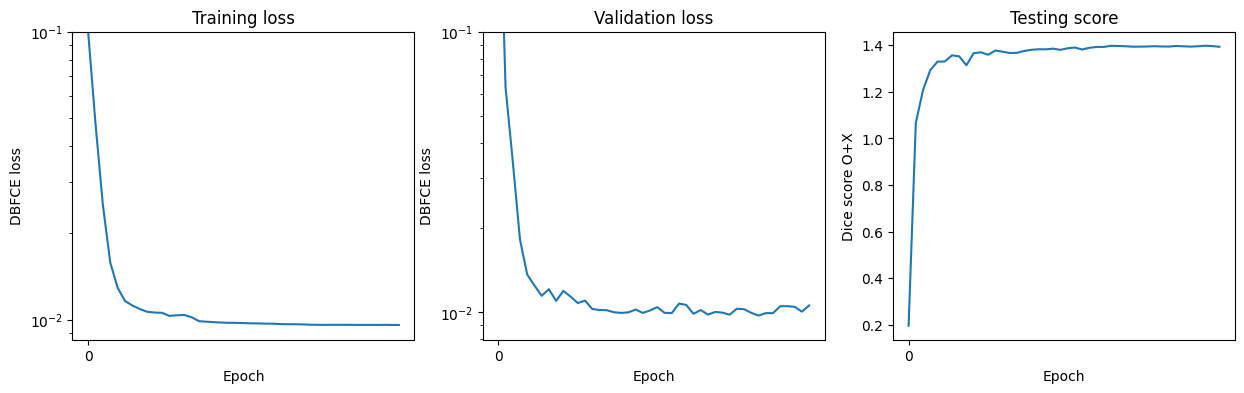

In [ ]:
# data = torch.load(saved_model_dir+sort_by_epoch[-1])
data = torch.load(saved_model_dir+'TOPHAT_checkpoint_epoch_43_18000_loss1.3933.pth')

test_losses = data['test_loss']
val_losses = data['val_loss']
losses = data['train_loss']

# data = torch.load('saved_model/'+'TOPHAT_checkpoint_epoch_30_25000_loss1.0700.pth')

# test_losses += data['test_loss']
# val_losses += data['val_loss']
# losses += data['train_loss']

fig, axs = plt.subplots(ncols=3, nrows=1, figsize=(15, 4))
ax = axs[0]
ax.plot(losses)
ax.set_xlabel('Epoch')
# ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_ylabel('DBFCE loss')
ax.set_title('Training loss')
ax.set_yscale('log')
ax.set_ylim(0,0.1)
# ax.set_yscale('log')
ax = axs[1]
ax.plot(val_losses)
ax.set_xlabel('Epoch')
# ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_ylabel('DBFCE loss')
ax.set_title('Validation loss')
ax.set_yscale('log')
ax.set_ylim(0,0.1)
# ax.set_yscale('log')
ax = axs[2]
ax.plot(test_losses)
# ax.plot([evalresult[t] for t in temp1])
ax.set_xlabel('Epoch')
# ax.set_xticks(np.arange(0,len(sort_by_loss)+1,4),[f'{t:.0f}' for t in np.arange(0,len(sort_by_loss)+1,4)*0.5])
ax.set_title('Testing score')
ax.set_ylabel('Dice score O+X')
# ax.set_ylim(1.5,1.7)

# ax.set_yscale('log')
# fig.savefig(f'losses.png', bbox_inches='tight')
# plt.close()

In [12]:
a = torch.tensor([0,0.5,0],dtype=torch.float32)
b = torch.tensor([1,0,0],dtype=torch.float32)
c = torch.logical_or(a,b)
print(c)
print(a,b)
c*torch.tensor([2,2,1])

tensor([ True,  True, False])
tensor([0.0000, 0.5000, 0.0000]) tensor([1., 0., 0.])


tensor([2, 2, 0])

In [12]:
# model = UNet(n_channels=3, n_classes=4, up_kernel_size=3)
target_size = [512,408]
model = UNet(n_channels=1, n_classes=4, input_size=target_size, in_dropout_p = 0.3, dropout_p=0.3)
# model = TransformerNet(n_channels=1, n_classes=4,input_size=target_size, in_dropout_p = 0.25, dropout_p=0.3)
# model.load_state_dict(torch.load('saved_model/TOPHAT_checkpoint_epoch_20_5_loss1.0486.pth')['model_state_dict'])
model.load_state_dict(torch.load(saved_model_dir+'TOPHAT_checkpoint_epoch_37_18000_loss1.3966.pth')['model_state_dict'])
model = model.to(device=device)
model.eval()

UNet(
  (att): Transformer(
    (in_linear): Linear(in_features=512, out_features=1024, bias=True)
    (out_linear): Linear(in_features=1024, out_features=1024, bias=True)
    (blocks): Sequential(
      (0): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=1024, out_features=1024, bias=True)
        )
        (relu): GELU(approximate='none')
        (ln): GroupNorm(1, 408, eps=1e-05, affine=True)
      )
      (1): Transformer_element(
        (c_attn): Linear(in_features=1024, out_features=3072, bias=False)
        (mlp): Sequential(
          (0): Linear(in_features=1024, out_features=1024, bias=False)
          (1): ReLU(inplace=True)
        )
        (mhatt): MultiheadAttention(
          (out_

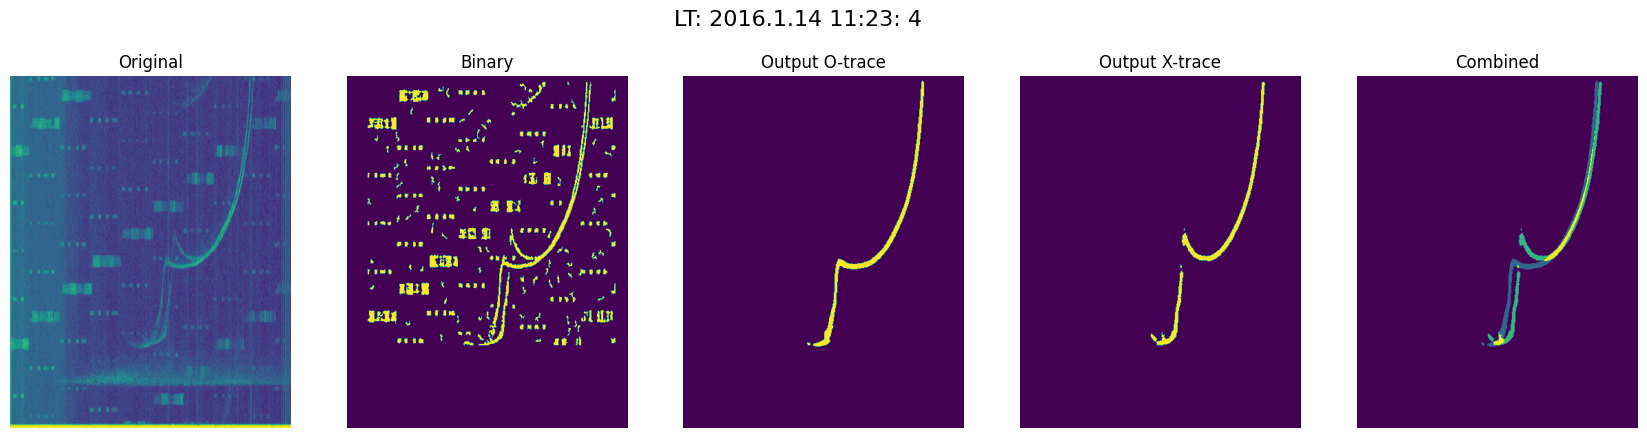

In [13]:
import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
    # for i in orgdata:
    #     print(i)
    timestruct = orgdata['vipirTimeSct']
    localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"

    # print(timestruct)
    
    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))
    # plt.title(f'epoch{epoch_num}_{file}')
    fig.suptitle(f'{localtime}', fontsize=16)

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[1]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[2]
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output O-trace')

    ax = axs[3]
    ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output X-trace')

    ax = axs[4]
    ax.imshow(imgO.numpy() + 2*imgX.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Combined')
# resize_back = transforms.Resize(ionogram.shape)


In [14]:
testdata = np.load('VIPIR_PROC/proc/' + testfiles[-1], allow_pickle=True, fix_imports=True)[()]
for i in testdata: print(i)

original
mask_full


In [15]:
d = np.load('JM91J_2016014141141.npy', allow_pickle=True)[()]
freqs = d['vipir_freqs']
hts = d['vipir_hts']

In [16]:
batchsize = 10

testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
all_filenames = []
all_imgOs = []
all_imgXs = []

with torch.inference_mode():
    for ii in range(len(testfiles)//batchsize):
        img = []
        names = []
        for jj in range(batchsize):
            file = testfiles[ii*batchsize + jj]
            testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]
            testimage = torch.from_numpy(testdata['mask_full']).float()
            testimage = testimage[None,None,:,:]
            img += [testimage]
            names += [file]

        img = torch.cat(img,dim=0)
        img = img.to('cuda')
        label = model(img)

        for i in range(batchsize):
            img1,label1 = img[i],label[i]
            label1 = label1.squeeze().to('cpu')
            imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().numpy()
            imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().numpy()
            all_filenames += [names[i]]
            all_imgOs += [imgO]
            all_imgXs += [imgX]
        # break
    del label; del img; del names    

def save_seg_result(idx, all_filenames, all_imgOs, all_imgXs):

    testdata = np.load('VIPIR_PROC/proc/' + all_filenames[idx], allow_pickle=True, fix_imports=True)[()]
    orgdata = np.load('VIPIR_PROC/org/' + all_filenames[idx], allow_pickle=True, fix_imports=True)[()]
    timestruct = orgdata['vipirTimeSct']
    localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"

    fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(22, 5))

    fig.suptitle(f'{localtime}',fontsize=16)

    ax = axs[0]
    ax.imshow(testdata['mask_full'], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binarized Ionogram')
    
    ax = axs[1]
    ax.imshow(all_imgOs[idx], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output O-trace')

    ax = axs[2]
    ax.imshow(all_imgXs[idx], origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Output X-trace')

    ax = axs[3]
    ax.pcolormesh(freqs,hts,all_imgOs[idx] + 2*all_imgXs[idx],shading='auto')
    ax.set_xlabel('Freq [MHz]')
    ax.set_ylabel('Heights [km]')
    # ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
    # ax.axis('off')
    ax.set_title('Combined')

    ax = axs[4]
    ax.pcolormesh(freqs,hts,np.log10(testdata['original']),shading='auto')
    ax.set_xlabel('Freq [MHz]')
    ax.set_ylabel('Heights [km]')
    # ax.imshow(np.log10(orgins[i]), origin='lower', aspect = 'equal')
    # ax.axis('off')
    ax.set_title('VIPIR Ionogram')

    plt.savefig(f'seg_result_transformer/{all_filenames[idx][:-4]}.png', bbox_inches='tight')
    plt.close()

    np.save(f'seg_result_transformer/{all_filenames[idx]}', {'filename':all_filenames[idx], 'imgO': all_imgOs[idx], 'imgX': all_imgXs[idx]})        


para_func = lambda idx: save_seg_result(idx, all_filenames, all_imgOs, all_imgXs)
# para_func(3)
losses = Parallel(n_jobs=mp.cpu_count()-4)(delayed(para_func)(idx) for idx in range(len(all_filenames)))

In [65]:
print(len(all_filenames))

1830


In [ ]:
# with torch.no_grad():
#     for file in testfiles:
#         # file = testfiles[np.random.randint(0,len(testfiles)-1)]
#         testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

#         testimage1 = torch.from_numpy(testdata['mask_full']).float()

#         orgdata = np.load('VIPIR_PROC/org/' + file, allow_pickle=True, fix_imports=True)[()]
#         timestruct = orgdata['vipirTimeSct']
#         localtime = f"LT: {timestruct['start_year'][0]:4d}.{timestruct['start_month'][0]:d}.{timestruct['start_day'][0]:d} {timestruct['start_hour'][0]-5:2d}:{timestruct['start_minute'][0]:2d}:{timestruct['start_second'][0]:2d}"
#         # testimage1 = resize_tr(testimage1[None,None,:,:])
#         # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
#         img = testimage1[None,None,:,:]
#         img = img.to('cuda')
#         label1 = model(img)
#         label1 = label1.squeeze().detach().cpu()

#         imgO = torch.argmax(label1[0:2,:,:],dim=0)
#         imgX = torch.argmax(label1[2:4,:,:],dim=0)
#         imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
#         imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
#         testimage1 = testimage1.detach().squeeze().numpy()
        
#         fig, axs = plt.subplots(ncols=5, nrows=1, figsize=(21, 5))

#         fig.suptitle(f'{localtime}',fontsize=16)


#         ax = axs[0]
#         ax.imshow(testimage1, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Binarized Ionogram')
        
#         ax = axs[1]
#         ax.imshow(imgO, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Output O-trace')

#         ax = axs[2]
#         ax.imshow(imgX, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Output X-trace')

#         ax = axs[3]
#         ax.imshow(imgO + 2*imgX, origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('Combined')

#         ax = axs[4]
#         ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal')
#         ax.axis('off')
#         ax.set_title('VIPIR Ionogram')

#         plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
#         plt.close()

#         np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})

In [ ]:


testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)
# resize_back = transforms.Resize(ionogram.shape)
# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    for file in testfiles:
        # file = testfiles[np.random.randint(0,len(testfiles)-1)]
        testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

        testimage1 = torch.from_numpy(testdata['mask_full']).float()
        # testimage1 = resize_tr(testimage1[None,None,:,:])
        # img = torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
        img = testimage1[None,None,:,:]
        img = img.to('cuda')
        label1 = model(img)
        label1 = label1.squeeze().detach().cpu()

        imgO = torch.argmax(label1[0:2,:,:],dim=0)
        imgX = torch.argmax(label1[2:4,:,:],dim=0)
        imgO = imgO[None,:,:].squeeze().numpy() # resize_back(imgO[None,:,:]).squeeze().numpy()
        imgX = imgX[None,:,:].squeeze().numpy() # resize_back(imgX[None,:,:]).squeeze().numpy()
        testimage1 = testimage1.detach().squeeze().numpy()
        
        fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(16, 7))
        plt.title(f'{file}')
        ax = axs[0]
        ax.imshow(testimage1, origin='lower', aspect = 'auto')
        ax.axis('off')
        ax = axs[1]

        ax.imshow(imgO + imgX*2, origin='lower', aspect = 'auto')
        ax.axis('off')

        plt.savefig(f'seg_result_transformer/{file[:-4]}.png', bbox_inches='tight')
        plt.close()

        np.save(f'seg_result_transformer/{file}', {'filename':file, 'image':testimage1, 'imgO': imgO, 'imgX': imgX})

In [ ]:
from scipy import ndimage
from skimage import morphology

import glob
testfiles = glob.glob1('VIPIR_PROC/proc/','*.npy')
# resize_tr = transforms.Resize((572, 572), antialias = False)

# testim = np.load('VIPIR_PROC/proc/' + testfiles[0], allow_pickle=True, fix_imports=True)[()]
# testim = torch.from_numpy(testim['mask_full']).float()
# XX, YY = torch.meshgrid(torch.linspace(0,1,572,dtype=torch.float32),torch.linspace(0,1,572,dtype=torch.float32))
 
with torch.no_grad():
    
    file = testfiles[np.random.randint(0,len(testfiles)-1)]
    testdata = np.load('VIPIR_PROC/proc/' + file, allow_pickle=True, fix_imports=True)[()]

    testimage1 = torch.from_numpy(testdata['mask_full']).float()
    testimage1 = testimage1[None,None,:,:]# resize_tr(testimage1[None,None,:,:])
    img = testimage1 #torch.cat([testimage1,XX[None,None,:,:],YY[None,None,:,:]],dim=-3)
    img = img.to('cuda')
    label1 = model(img)
    label1 = label1.squeeze().to('cpu')
    # transform = transforms.ToPILImage()
    # img = transform(label1)
    imgO = torch.argmax(label1[0:2,:,:],dim=0).detach().cpu()
    imgX = torch.argmax(label1[2:4,:,:],dim=0).detach().cpu()
    
    original = testdata['original']
    original -= (np.min(original)-1)
    original[np.isnan(original)] = 1

    temp1 = np.log10(original)

    sigma1 = 0.85
    sigma2 = 3

    gauss1 = ndimage.gaussian_filter(temp1,sigma1)
    gauss2 = ndimage.gaussian_filter(temp1,sigma2)
    out = gauss1-gauss2

    thresh = out > np.percentile(out,80,axis=0)
    
    temp3 = morphology.remove_small_objects(thresh, min_size=20, connectivity=1)
    # structure = np.ones([3,1])
    # temp = ndimage.binary_closing(temp3, structure)

    fig, axs = plt.subplots(ncols=4, nrows=1, figsize=(21, 7))
    # plt.title(f'epoch{epoch_num}_{file}')

    ax = axs[0]
    ax.imshow(np.log10(testdata['original']), origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Original')

    ax = axs[2]
    ax.imshow(testimage1.detach().squeeze(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Binary')
    
    ax = axs[1]
    ax.imshow(out, origin='lower', aspect = 'equal', cmap='gray')
    ax.axis('off')
    ax.set_title('Difference of Gaussian')

    # ax = axs[3]
    # ax.imshow(imgX.numpy(), origin='lower', aspect = 'equal')
    # ax.axis('off')
    # ax.set_title('Output X-trace')

    ax = axs[3]
    imgO[imgX>0] = 2
    ax.imshow(imgO.numpy(), origin='lower', aspect = 'equal')
    ax.axis('off')
    ax.set_title('Segmentation')

# resize_back = transforms.Resize(ionogram.shape)